Note: you may need to restart the kernel to use updated packages.
Dataset shape: (17, 4)


,Metric,Apex Frozen Foods Ltd,Sharat Industries Ltd,The Waterbase Ltd
0,Ticker,APEX (NSE) / 540692 (BSE),SHINDL (NSE/BSE),WATERBASE (NSE/BSE)
1,Core business,Processed and branded shrimp exports,"Integrated hatchery, farming, feed, processing...","Shrimp feed, farm-care products and aquacultur..."
2,Approx. share price (INR),331,158,44
3,Approx. market capitalisation (INR crore),1036,618,176
4,FY26 revenue (INR crore),931,525,350


Best K: 7
Silhouette score: 0.0454
Cluster
0    3
1    3
2    1
3    2
4    2
5    4
6    2
Name: count, dtype: int64


,Metric,Apex Frozen Foods Ltd,Sharat Industries Ltd,The Waterbase Ltd,Cluster
0,Ticker,APEX (NSE) / 540692 (BSE),SHINDL (NSE/BSE),WATERBASE (NSE/BSE),2
1,Core business,Processed and branded shrimp exports,"Integrated hatchery, farming, feed, processing...","Shrimp feed, farm-care products and aquacultur...",1
2,Approx. share price (INR),331,158,44,5
3,Approx. market capitalisation (INR crore),1036,618,176,5
4,FY26 revenue (INR crore),931,525,350,0


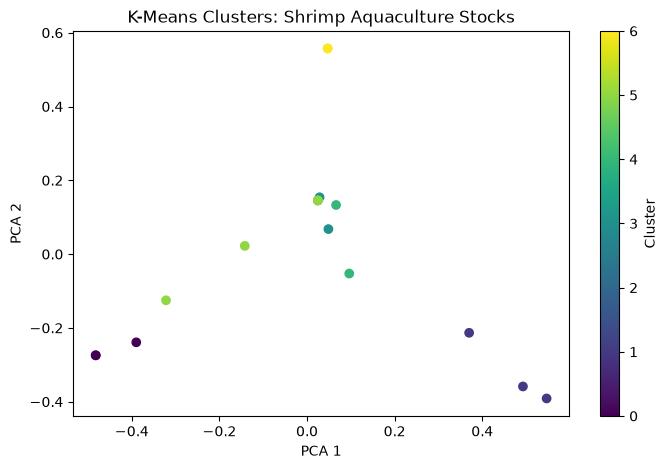

Saved: Shrimp_Aquaculture_KMeans_NLP_Results.csv


In [1]:
# 1. Install libraries
%pip install -q pandas numpy matplotlib scikit-learn scipy

# 2. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import hstack, csr_matrix
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# 3. Load dataset
df = pd.read_csv("Indian_Shrimp_Aquaculture_Stocks_Comparison.csv")
df.columns = df.columns.astype(str).str.strip()
df = df.drop_duplicates().dropna(axis=1, how="all")
df = df.replace(r"^\s*$", np.nan, regex=True)

print("Dataset shape:", df.shape)
display(df.head())

# 4. Detect numerical and text columns
num_cols = df.select_dtypes(include=np.number).columns.tolist()
text_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()

# Exclude identifiers manually if necessary
exclude = []  # Example: ["Company", "Ticker", "Date"]
num_cols = [c for c in num_cols if c not in exclude]
text_cols = [c for c in text_cols if c not in exclude]

features = []

# 5. Preprocess numerical features
if num_cols:
    numeric = df[num_cols].apply(pd.to_numeric, errors="coerce")
    numeric = numeric.loc[:, numeric.notna().any()]
    if numeric.shape[1]:
        numeric = SimpleImputer(strategy="median").fit_transform(numeric)
        numeric = StandardScaler().fit_transform(numeric)
        features.append(csr_matrix(numeric))

# 6. NLP with TF-IDF
if text_cols:
    text = df[text_cols].fillna("").astype(str).agg(" ".join, axis=1)
    try:
        tfidf = TfidfVectorizer(
            stop_words="english", max_features=2000, ngram_range=(1, 2)
        )
        text_features = tfidf.fit_transform(text)
        if text_features.shape[1]:
            features.append(text_features)
    except ValueError:
        print("No usable text for NLP; continuing with numerical data.")

# 7. Combine features
if not features:
    raise ValueError("No usable numerical or text features found.")

X = hstack(features, format="csr")
if X.shape[0] < 3:
    raise ValueError("At least 3 rows are recommended.")

# 8. Find best K using silhouette score
scores = {}
for k in range(2, min(8, X.shape[0])):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)
    if len(set(labels)) > 1:
        scores[k] = silhouette_score(
            X, labels,
            sample_size=min(2000, X.shape[0]),
            random_state=42
        )

best_k = max(scores, key=scores.get) if scores else 2
print("Best K:", best_k)
if scores:
    print("Silhouette score:", round(scores[best_k], 4))

# 9. Final K-Means clustering
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X)

print(df["Cluster"].value_counts().sort_index())
display(df.head())

# 10. PCA visualisation
X_dense = X.toarray()
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_dense)

plt.figure(figsize=(8, 5))
plt.scatter(coords[:, 0], coords[:, 1], c=df["Cluster"], cmap="viridis")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("K-Means Clusters: Shrimp Aquaculture Stocks")
plt.colorbar(label="Cluster")
plt.show()

# 11. Cluster summary
if num_cols:
    display(df.groupby("Cluster")[num_cols].mean().round(2))

# 12. Export results
df.to_csv("Shrimp_Aquaculture_KMeans_NLP_Results.csv", index=False)
print("Saved: Shrimp_Aquaculture_KMeans_NLP_Results.csv")